In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import halotools
from halotools.sim_manager import DownloadManager
from halotools.empirical_models import PrebuiltSubhaloModelFactory
from halotools.sim_manager import CachedHaloCatalog
from halotools.mock_observables import return_xyz_formatted_array
from halotools.mock_observables import tpcf 
from halotools.mock_observables import tpcf_one_two_halo_decomp

from halotools.utils import group_member_generator # iterates over galaxy population on a group-by-group basis
from halotools.mock_observables import mean_y_vs_x # convenience function used for quick exploratory work?
print(halotools.__version__)

0.9.2


In [2]:
# DownloadManager Tutorial
# dman = DownloadManager()
# dman.download_processed_halo_table('bolshoi', 'rockstar', 0,overwrite=True)

In [3]:
# Generating a mock galaxy catalog into an N-body simulation
model = PrebuiltSubhaloModelFactory('smhm_binary_sfr')
halocat = CachedHaloCatalog(simname = 'bolshoi', redshift = 0, halo_finder = 'rockstar')
model.populate_mock(halocat)

In [ ]:
# Calculate Two-point clustering # Center of halos (will be working with halos not galaxies)
x = model.mock.galaxy_table['x']
y = model.mock.galaxy_table['y']
z = model.mock.galaxy_table['z']
sample_mask = model.mock.galaxy_table['stellar_mass'] > 1e10
pos = return_xyz_formatted_array(x, y, z, mask = sample_mask)
rbins = np.logspace(-1, 1.25, 15) 
rbin_centers = (rbins[1:] + rbins[:-1])/2.
xi_all = tpcf(pos, rbins, period = model.mock.Lbox, num_threads = 'max') # period  = size of simulation  (size of the box)

: 

In [ ]:
# Decomposition in 1-halo and 2-halo terms

halo_hostid = model.mock.galaxy_table['halo_hostid'][sample_mask]

xi_1h, xi_2h = tpcf_one_two_halo_decomp(pos,
                halo_hostid, rbins,
                period = model.mock.Lbox,
                num_threads='max')


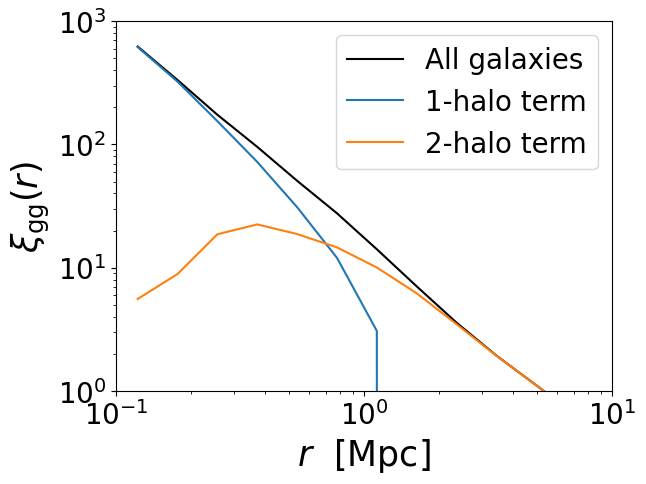

In [ ]:
# Plot the results
plt.plot(rbin_centers, xi_all,
         label='All galaxies', color='k')
plt.plot(rbin_centers, xi_1h,
         label = '1-halo term')
plt.plot(rbin_centers, xi_2h,
         label = '2-halo term')

plt.xlim(xmin = 0.1, xmax = 10)
plt.ylim(ymin = 1, ymax = 1e3)
plt.loglog()
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlabel(r'$r $  $\rm{[Mpc]}$', fontsize=25)
plt.ylabel(r'$\xi_{\rm gg}(r)$', fontsize=25)
plt.legend(loc='best', fontsize=20)

In [ ]:
gals = model.mock.galaxy_table[sample_mask]
print(gals)

# Adding halo_total_stellar_mass column to our table gals

gals.sort('halo_hostid')
grouping_key = 'halo_hostid' # natural grouping key for a galaxy catalog whose host halos are known
requested_columns = ['stellar_mass']
group_gen = group_member_generator(gals, grouping_key, requested_columns)

total_stellar_mass = np.zeros(len(gals))
for first, last, member_props in group_gen:
    stellar_mass_of_members = member_props[0]
    total_stellar_mass[first:last] = sum(stellar_mass_of_members)

gals['halo_total_stellar_mass'] = total_stellar_mass

# Want to broadcast host halo mass to host halo members
gals.sort(['halo_hostid', 'halo_upid']) # two property sort
grouping_key = 'halo_hostid'
requested_columns = ['halo_mvir']
group_gen = group_member_generator(gals, grouping_key, requested_columns)

host_mass = np.zeros(len(gals))
for first, last, member_props in group_gen:
    mvir_members = member_props[0]
    mvir_host = mvir_members[0]
    host_mass[first:last] = mvir_host

gals['halo_mhost'] = host_mass # Our gals table now has a halo_mhost column

# Compute the mean total stellar mass in bins of halo mass

bins = np.logspace(12, 15, 25)
result = mean_y_vs_x(gals['halo_mhost'].data,
                     gals['halo_total_stellar_mass'].data,
                     bins = bins,
                     error_estimator = 'variance')

host_mass, mean_stellar_mass, mean_stellar_mass_err = result

In [ ]:
plt.errorbar(host_mass, mean_stellar_mass, yerr=mean_stellar_mass_err,
             fmt = "none", ecolor='gray')
plt.plot(host_mass, mean_stellar_mass, 'D', color='k')

plt.loglog()
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel(r'$M_{\rm halo}/M_{\odot}$', fontsize=25)
plt.ylabel(r'$\langle M_{\ast}^{\rm tot}/M_{\odot}\rangle$', fontsize=25)
plt.ylim(ymax=5e12)

In [ ]:
# Quiescent (inactive) fraction of centrals and satellites
cens_mask = gals['halo_upid'] == -1
cens = gals[cens_mask]
sats = gals[~cens_mask]

bins = np.logspace(12, 14.5, 15)

# centrals
result = mean_y_vs_x(cens['halo_mhost'].data, cens['quiescent'].data,
            bins = bins)
host_mass, fq_cens, fq_cens_err_on_mean = result

# satellites
result = mean_y_vs_x(sats['halo_mhost'].data, sats['quiescent'].data,
            bins = bins)
host_mass, fq_sats, fq_sats_err_on_mean = result

In [ ]:
# Plot the results
plt.errorbar(host_mass, fq_cens, yerr=fq_cens_err_on_mean,
             color='seagreen', fmt = "none")
plt.plot(host_mass, fq_cens, 'D', color='seagreen',
             label = 'galaxy population')

analytic_result_mhost_bins = np.logspace(10, 15.5, 100)
analytic_result_mean_quiescent_fraction = model.mean_quiescent_fraction(prim_haloprop = analytic_result_mhost_bins)
plt.plot(analytic_result_mhost_bins,
         analytic_result_mean_quiescent_fraction,
         color='blue', label = 'analytical model')

plt.xscale('log')
plt.xticks(size=22)
plt.yticks(size=18)
plt.xlabel(r'$M_{\rm halo}/M_{\odot}$', fontsize=25)
plt.ylabel('quiescent fraction', fontsize=20)
plt.xlim(xmin = 1e12, xmax = 1e15)
plt.ylim(ymin = 0.2, ymax=0.8)
plt.legend(frameon=False, loc='best', fontsize=20)
plt.title('Central galaxy quenching: model vs. mock', fontsize=17)